# Módulo 2 · Quedarse solo con umbral y reinicio (LIF)

La neurona de integración y disparo con fuga conserva la membrana pasiva y reemplaza el disparo por una regla:

$$\tau_m\frac{dV}{dt} = -(V-E_L) + R_m I, \qquad V\ge V_{th} \Rightarrow \text{disparo},\ V\leftarrow V_{reset}$$

Como la ecuación es lineal, su frecuencia de disparo tiene una fórmula exacta, que nos permite **poner a prueba el método numérico** frente a la verdad:

$$f(I) = \Big[t_{ref} + \tau_m\ln\frac{R_mI}{R_mI-(V_{th}-E_L)}\Big]^{-1}$$

In [1]:
import sys, inspect
sys.path.insert(0, '..')            # make the neurosim package importable
import numpy as np
import matplotlib.pyplot as plt
import neurosim as ns
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

In [2]:
print(inspect.getsource(ns.simulate_lif))

def simulate_lif(stimulus, duration=100.0, dt=0.1, params=None, spike_height=20.0):
    """tau_m dV/dt = -(V - E_L) + R_m I. When V crosses V_th a spike is
    recorded, V is reset to V_reset and held there for t_ref ms.

    For display only, the sample at the crossing is drawn at `spike_height`.
    Returns dict with ``t, V, spikes``.
    """
    p = dict(LIF_CELL, **(params or {}))
    drive = stimulus if callable(stimulus) else (lambda _t: stimulus)
    n_steps = int(round(duration / dt))
    t = np.arange(n_steps) * dt
    V = np.full(n_steps, p["E_L"])
    spikes = []
    hold_until = -1.0
    for i in range(n_steps - 1):
        if t[i] < hold_until:                       # absolute refractory period
            V[i + 1] = p["V_reset"]
            continue
        dV = (-(V[i] - p["E_L"]) + p["R_m"] * drive(t[i])) / p["tau_m"]
        V[i + 1] = V[i] + dt * dV
        if V[i + 1] >= p["V_th"]:
            spikes.append(t[i + 1])
            V[i + 1] = spike_height
            ho

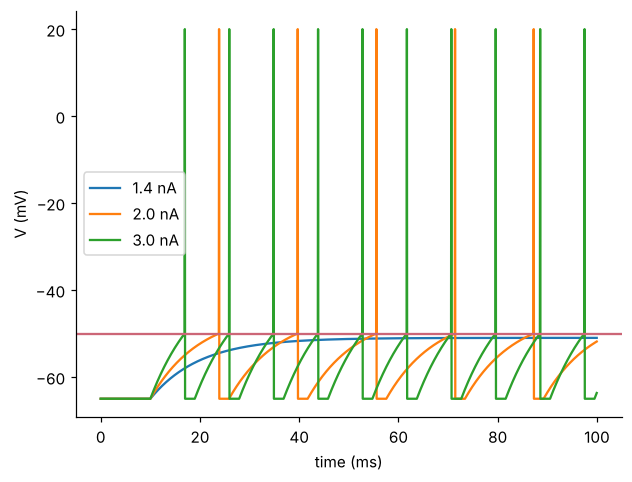

In [3]:
for I in (1.4, 2.0, 3.0):
    r = ns.simulate_lif(lambda t, I=I: I if t >= 10 else 0.0, 100, dt=0.05)
    plt.plot(r['t'], r['V'], label=f'{I} nA')
plt.axhline(ns.LIF_CELL['V_th'], color='#CC6677'); plt.legend(); plt.xlabel('time (ms)'); plt.ylabel('V (mV)'); plt.show()

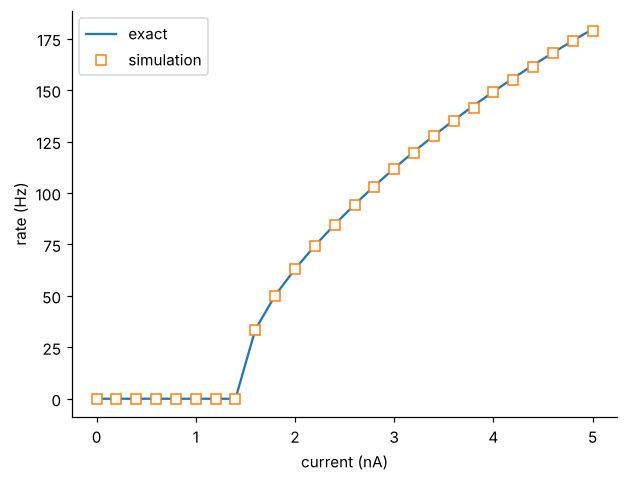

rheobase = 1.5 nA


In [4]:
I = np.linspace(0, 5, 26)
sim = [ns.simulate_lif(i, 2000, dt=0.05)['spikes'].size / 2.0 for i in I]
plt.plot(I, ns.lif_rate_closed_form(I), label='exact'); plt.plot(I, sim, 's', mfc='white', label='simulation')
plt.xlabel('current (nA)'); plt.ylabel('rate (Hz)'); plt.legend(); plt.show()
print('rheobase =', (ns.LIF_CELL['V_th'] - ns.LIF_CELL['E_L']) / ns.LIF_CELL['R_m'], 'nA')

## Ejercicios
1. Repite la comparación con `dt=0.5` y `dt=1.0`. ¿Qué tan grande es el error? ¿Por qué un paso grueso subestima la frecuencia?
2. Deduce la reobase $I_{rh}=(V_{th}-E_L)/R_m$ a partir del estado estacionario de la ecuación.
3. Usa `params={'t_ref': 0}`. ¿Qué limita ahora la frecuencia?
4. Compara esta curva f-I con la del Módulo 1. Nombra dos comportamientos de la célula de Hodgkin-Huxley que el LIF no puede mostrar.